# Sécurité routière — accidents corporels en France (2021-2023)

**Source** : [Bases de données annuelles des accidents corporels de la circulation routière](https://www.data.gouv.fr/datasets/bases-de-donnees-annuelles-des-accidents-corporels-de-la-circulation-routiere-annees-de-2005-a-2024) — ONISR / data.gouv.fr. Fichier BAAC (Bulletin d'Analyse des Accidents Corporels), 4 tables par année : `Caractéristiques`, `Lieux`, `Véhicules`, `Usagers`.

**Question traitée** : *Quand, où et dans quelles conditions les accidents graves surviennent-ils ?*

**Périmètre** : 2021 à 2023 (3 années), France entière (métropole + outre-mer). Un **accident grave** est défini ici comme un accident corporel comptant au moins un usager tué ou blessé hospitalisé (`grav` = 2 ou 3 dans la table `Usagers`).

Ce notebook documente le pipeline SQL (jointures, nettoyage) et l'analyse, étape par étape : chaque requête est suivie de son résultat.


In [1]:
import sqlite3
import pandas as pd

pd.set_option("display.max_rows", 20)
conn = sqlite3.connect("/home/claude/accidents/accidents.db")


## 1. Jointures et nettoyage

Les 4 tables se joignent sur la clé `Num_Acc`, commune à toutes. Deux points de vigilance rencontrés en chargeant les 12 CSV (2021-2023 × 4 fichiers) :

1. **`Caractéristiques` 2022 nomme sa clé `Accident_Id` au lieu de `Num_Acc`** (même colonne, même rôle) — les autres années et les autres tables utilisent `Num_Acc`. Il faut harmoniser le nom de colonne au chargement pour pouvoir fusionner les 3 années.
2. **`Lieux` n'est pas toujours à la granularité 1 ligne = 1 accident** : environ 29 % des accidents ont 2 lignes (parfois plus) dans `Lieux`, typiquement pour un accident à une intersection de deux voies (une ligne par voie). Exemple vérifié : l'accident `202300000001` a deux lignes `Lieux`, une pour "RUE DE RIVOLI", une pour "RUE SAINT FLORENTIN".

   → Pour les jointures 1-pour-1 avec `Caractéristiques` (poser une question par accident, pas par voie), on garde la **première ligne `Lieux` par accident** (vue `lieux_dedup`), ce qui couvre l'intégralité des accidents sans les dupliquer. La table `Lieux` brute reste disponible pour une analyse fine par voie si besoin.


In [2]:
pd.read_sql_query('''
    SELECT Num_Acc, catr, voie FROM lieux WHERE Num_Acc = "202300000001"
''', conn)


,Num_Acc,catr,voie
0,202300000001,4,RUE DE RIVOLI
1,202300000001,4,RUE SAINT FLORENTIN


In [3]:
cur = conn.cursor()
cur.executescript('''
DROP VIEW IF EXISTS accidents_graves;
CREATE VIEW accidents_graves AS
SELECT DISTINCT Num_Acc FROM usagers WHERE grav IN (2,3);

DROP VIEW IF EXISTS lieux_dedup;
CREATE VIEW lieux_dedup AS
SELECT * FROM lieux WHERE rowid IN (SELECT MIN(rowid) FROM lieux GROUP BY Num_Acc);
''')
conn.commit()
print("Vues 'accidents_graves' et 'lieux_dedup' créées.")


Vues 'accidents_graves' et 'lieux_dedup' créées.


## 2. Vue d'ensemble (2021-2023)


In [4]:
pd.read_sql_query('''
    SELECT
        c.annee,
        COUNT(*) AS accidents,
        SUM(CASE WHEN g.Num_Acc IS NOT NULL THEN 1 ELSE 0 END) AS accidents_graves,
        ROUND(100.0 * SUM(CASE WHEN g.Num_Acc IS NOT NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_graves
    FROM caracteristiques c
    LEFT JOIN accidents_graves g ON g.Num_Acc = c.Num_Acc
    GROUP BY c.annee
    ORDER BY c.annee
''', conn)


,annee,accidents,accidents_graves,pct_graves
0,2021,56518,19553,34.6
1,2022,55302,19911,36.0
2,2023,54822,19785,36.1


Sur les 3 ans, **166 642 accidents corporels**, dont **35,6 % classés graves** (au moins un tué ou blessé hospitalisé). Le taux est stable d'une année sur l'autre — la suite croise ce taux avec le moment, le lieu et les conditions pour voir où il s'écarte fortement de cette moyenne.


## 3. Quand les accidents graves surviennent-ils ?

### Par heure de la journée


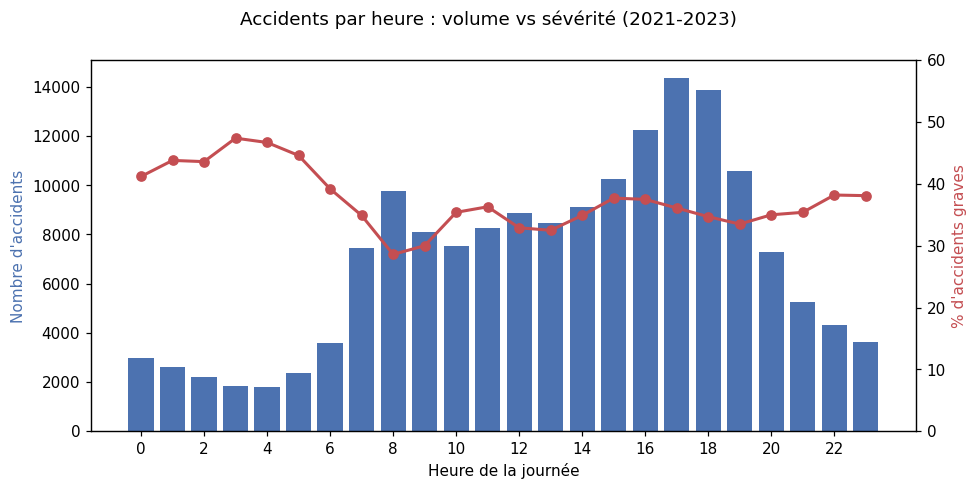

,heure,total,graves,pct_graves
0,0,2987,1231,41.2
1,1,2595,1136,43.8
2,2,2197,958,43.6
3,3,1829,867,47.4
4,4,1799,840,46.7
5,5,2353,1049,44.6
6,6,3605,1412,39.2
7,7,7431,2596,34.9
8,8,9786,2796,28.6
9,9,8113,2435,30.0


In [5]:
df_heure = pd.read_sql_query('''
    SELECT
        CAST(substr(c.hrmn,1,2) AS INTEGER) AS heure,
        COUNT(*) AS total,
        SUM(CASE WHEN g.Num_Acc IS NOT NULL THEN 1 ELSE 0 END) AS graves,
        ROUND(100.0 * SUM(CASE WHEN g.Num_Acc IS NOT NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_graves
    FROM caracteristiques c
    LEFT JOIN accidents_graves g ON g.Num_Acc = c.Num_Acc
    GROUP BY heure ORDER BY heure
''', conn)

fig, ax1 = plt.subplots(figsize=(9, 4.5))
ax1.bar(df_heure["heure"], df_heure["total"], color="#4C72B0", label="Accidents (total)")
ax1.set_xlabel("Heure de la journée")
ax1.set_ylabel("Nombre d'accidents", color="#4C72B0")
ax1.set_xticks(range(0, 24, 2))

ax2 = ax1.twinx()
ax2.plot(df_heure["heure"], df_heure["pct_graves"], color="#C44E52", marker="o", linewidth=2, label="% graves")
ax2.set_ylabel("% d'accidents graves", color="#C44E52")
ax2.set_ylim(0, 60)

fig.suptitle("Accidents par heure : volume vs sévérité (2021-2023)")
fig.tight_layout()
plt.show()

df_heure


Deux dynamiques très différentes se superposent :
- **Le volume d'accidents** suit les déplacements (pointes à 8h, 12h et surtout 16h-18h, creux entre 2h et 5h).
- **Le taux de gravité** suit la courbe inverse : il est **le plus élevé la nuit** (autour de 40-45 % entre 0h et 5h) alors que le volume y est le plus faible, et retombe vers 35 % aux heures de pointe. Moins d'accidents la nuit, mais nettement plus souvent graves — cohérent avec des vitesses plus élevées et une visibilité réduite sur routes peu fréquentées.


### Par mois (saisonnalité)


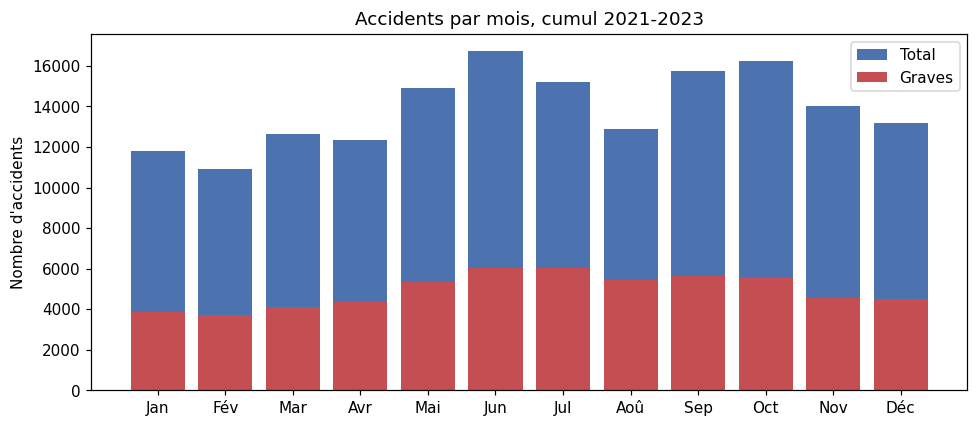

In [6]:
df_mois = pd.read_sql_query('''
    SELECT c.mois,
        COUNT(*) AS total,
        SUM(CASE WHEN g.Num_Acc IS NOT NULL THEN 1 ELSE 0 END) AS graves
    FROM caracteristiques c
    LEFT JOIN accidents_graves g ON g.Num_Acc = c.Num_Acc
    GROUP BY c.mois ORDER BY c.mois
''', conn)

fig, ax = plt.subplots(figsize=(9, 4))
mois_labels = ["Jan","Fév","Mar","Avr","Mai","Jun","Jul","Aoû","Sep","Oct","Nov","Déc"]
ax.bar(mois_labels, df_mois["total"], color="#4C72B0", label="Total")
ax.bar(mois_labels, df_mois["graves"], color="#C44E52", label="Graves")
ax.set_ylabel("Nombre d'accidents")
ax.set_title("Accidents par mois, cumul 2021-2023")
ax.legend()
fig.tight_layout()
plt.show()


Nette saisonnalité : les mois de **mai à octobre** concentrent le plus d'accidents (trafic de loisirs, deux-roues, vacances), avec un pic en juin. Janvier et février sont les mois les plus calmes.


## 4. Où les accidents graves surviennent-ils ?

### Par catégorie de route


In [7]:
CATR = {1:"Autoroute",2:"Nationale",3:"Départementale",4:"Voie communale",
        5:"Hors réseau public",6:"Parking public",7:"Métropole urbaine",9:"Autre"}

df_catr = pd.read_sql_query('''
    SELECT l.catr, COUNT(*) AS total,
        SUM(CASE WHEN g.Num_Acc IS NOT NULL THEN 1 ELSE 0 END) AS graves,
        ROUND(100.0 * SUM(CASE WHEN g.Num_Acc IS NOT NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_graves
    FROM caracteristiques c
    JOIN lieux_dedup l ON l.Num_Acc = c.Num_Acc
    LEFT JOIN accidents_graves g ON g.Num_Acc = c.Num_Acc
    GROUP BY l.catr ORDER BY total DESC
''', conn)
df_catr["libelle"] = df_catr["catr"].map(CATR)
df_catr[["libelle", "total", "graves", "pct_graves"]]


,libelle,total,graves,pct_graves
0,Voie communale,69429,16547,23.8
1,Départementale,62406,31558,50.6
2,Autoroute,15614,3645,23.3
3,Nationale,10680,4365,40.9
4,Métropole urbaine,6288,2178,34.6
5,Parking public,1199,476,39.7
6,Autre,841,388,46.1
7,Hors réseau public,185,92,49.7


Grand écart de sévérité selon le type de route :
- **Routes départementales : 50,6 % d'accidents graves** — et c'est la 2ᵉ catégorie en volume (62 406 accidents). C'est de loin la plus préoccupante : beaucoup d'accidents, et un sur deux est grave (vitesses élevées, routes à une chaussée, parfois sans séparateur central).
- **Voies communales et autoroutes : ~24 % de graves** — volume élevé mais sévérité contenue (vitesse limitée en ville ; sécurité structurelle de l'autoroute malgré la vitesse).

### Par département (top 10, en volume d'accidents graves)


In [8]:
df_dep = pd.read_sql_query('''
    SELECT c.dep, COUNT(*) AS total,
        SUM(CASE WHEN g.Num_Acc IS NOT NULL THEN 1 ELSE 0 END) AS graves,
        ROUND(100.0 * SUM(CASE WHEN g.Num_Acc IS NOT NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_graves
    FROM caracteristiques c
    LEFT JOIN accidents_graves g ON g.Num_Acc = c.Num_Acc
    GROUP BY c.dep ORDER BY graves DESC LIMIT 10
''', conn)
df_dep


,dep,total,graves,pct_graves
0,13,7091,2168,30.6
1,69,6556,1438,21.9
2,59,3188,1402,44.0
3,83,2482,1390,56.0
4,33,3881,1314,33.9
5,34,1809,1173,64.8
6,75,14903,1111,7.5
7,38,1994,1099,55.1
8,06,2634,1077,40.9
9,62,1560,1040,66.7


Le classement par **volume** d'accidents graves est dominé par les départements très peuplés (Bouches-du-Rhône, Rhône, Paris...). Mais le **taux** de gravité raconte une autre histoire : Paris (75) cumule 14 903 accidents sur la période mais seulement **7,5 % sont graves** — la densité urbaine limite la vitesse donc la gravité, même si les accidents y sont fréquents. À l'inverse, des départements plus ruraux comme le Pas-de-Calais (62, 66,7 %) ou l'Hérault (34, 64,8 %) ont beaucoup moins d'accidents en volume mais un accident sur deux à deux sur trois y est grave.

→ Volume élevé et dangerosité élevée ne vont pas de pair : Paris est le cas le plus net (fréquence élevée, gravité faible), l'inverse pour certains départements ruraux/routiers.


## 5. Dans quelles conditions ?

### Luminosité


In [9]:
LUM = {1:"Plein jour",2:"Crépuscule/aube",3:"Nuit sans éclairage",4:"Nuit, écl. éteint",5:"Nuit, écl. allumé",-1:"Non renseigné"}

df_lum = pd.read_sql_query('''
    SELECT lum, COUNT(*) AS total,
        SUM(CASE WHEN g.Num_Acc IS NOT NULL THEN 1 ELSE 0 END) AS graves,
        ROUND(100.0 * SUM(CASE WHEN g.Num_Acc IS NOT NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_graves
    FROM caracteristiques c
    LEFT JOIN accidents_graves g ON g.Num_Acc = c.Num_Acc
    GROUP BY lum ORDER BY total DESC
''', conn)
df_lum["libelle"] = df_lum["lum"].map(LUM)
df_lum[["libelle", "total", "graves", "pct_graves"]]


,libelle,total,graves,pct_graves
0,Plein jour,112239,38611,34.4
1,"Nuit, écl. allumé",25255,6751,26.7
2,Nuit sans éclairage,16521,8865,53.7
3,Crépuscule/aube,11011,4376,39.7
4,"Nuit, écl. éteint",1612,644,40.0
5,Non renseigné,4,2,50.0


La **nuit sans éclairage public concentre à la fois peu d'accidents (16 521, le 3ᵉ cas le plus rare) et le taux de gravité le plus élevé (53,7 %)** — cohérent avec le pic nocturne observé en heure. La nuit *avec* éclairage allumé retombe à 26,7 %, l'écart le plus net de tout le jeu de conditions étudiées.

### Météo et état de la chaussée


In [10]:
ATM = {1:"Normale",2:"Pluie légère",3:"Pluie forte",4:"Neige/grêle",5:"Brouillard/fumée",
       6:"Vent fort",7:"Temps éblouissant",8:"Couvert",9:"Autre",-1:"Non renseigné"}

df_atm = pd.read_sql_query('''
    SELECT atm, COUNT(*) AS total,
        SUM(CASE WHEN g.Num_Acc IS NOT NULL THEN 1 ELSE 0 END) AS graves,
        ROUND(100.0 * SUM(CASE WHEN g.Num_Acc IS NOT NULL THEN 1 ELSE 0 END) / COUNT(*), 1) AS pct_graves
    FROM caracteristiques c
    LEFT JOIN accidents_graves g ON g.Num_Acc = c.Num_Acc
    GROUP BY atm ORDER BY total DESC
''', conn)
df_atm["libelle"] = df_atm["atm"].map(ATM)
df_atm[["libelle", "total", "graves", "pct_graves"]]


,libelle,total,graves,pct_graves
0,Normale,133050,47462,35.7
1,Pluie légère,17601,5176,29.4
2,Couvert,6407,2177,34.0
3,Pluie forte,3635,1333,36.7
4,Temps éblouissant,3087,1638,53.1
5,Brouillard/fumée,1169,637,54.5
6,Autre,764,371,48.6
7,Neige/grêle,490,210,42.9
8,Vent fort,426,239,56.1
9,Non renseigné,13,6,46.2


La météo normale domine très largement le volume (133 050 accidents, 80 % du total) avec un taux de gravité de 35,7 % — proche de la moyenne générale, ce qui est attendu puisqu'elle concentre l'essentiel des trajets. Les conditions dégradées (vent fort, brouillard, temps éblouissant) affichent des taux de gravité plus élevés (48 à 56 %), mais sur des effectifs beaucoup plus restreints (quelques centaines à ~3 000 accidents) : la tendance est cohérente avec l'intuition (visibilité réduite → accidents plus graves), mais ces pourcentages reposent sur peu d'observations et doivent être lus comme indicatifs, pas comme une statistique aussi robuste que pour la luminosité ou le type de route.


## 6. Synthèse

**Réponse à la question** — les accidents graves ne se répartissent pas comme les accidents en général :

- **Quand** : la nuit (surtout sans éclairage public) est largement sous-représentée en volume mais surreprésentée en gravité. Saisonnalité marquée, pic de mai à octobre.
- **Où** : les routes départementales cumulent volume élevé *et* sévérité élevée (50,6 % de graves) — la priorité la plus claire du jeu de données. Les grandes villes (Paris en tête) ont beaucoup d'accidents mais peu graves ; l'inverse pour des départements plus ruraux.
- **Conditions** : l'absence d'éclairage nocturne est le facteur isolé le plus net. Les conditions météo dégradées vont dans le même sens mais sur des volumes trop faibles pour trancher seules.

**Pistes de prévention qui ressortent des données** (hypothèses à confirmer par des experts du domaine, pas des recommandations définitives) :
- Vitesse et éclairage sur routes départementales la nuit — la combinaison la plus associée à la gravité dans ce jeu de données.
- Les grandes agglomérations montrent qu'une fréquence d'accidents élevée n'implique pas une gravité élevée — à l'inverse, le couple route rurale + nuit mérite l'attention prioritaire.

### Limites connues
- **Pas de dénominateur d'exposition** : ce jeu de données compte des accidents, pas de trafic (ex. véhicules·km parcourus). Un département avec plus d'accidents n'est pas forcément plus dangereux par trajet — il peut juste avoir plus de circulation. Les taux de gravité (%) partiellement corrigent ce biais entre catégories, mais pas les comparaisons de *volume* brut.
- **Définition "accident grave"** : choix du seuil tué + blessé hospitalisé (`grav` 2 et 3). La base ONISR précise que la qualification "blessé hospitalisé" n'est plus comparable d'une année sur l'autre depuis 2018 et n'est plus labellisée par l'autorité de la statistique publique depuis 2019 — à garder en tête si on affine ce travail.
- **Causalité non établie** : les écarts observés (nuit, route départementale, météo) sont des corrélations dans les données déclarées par les forces de l'ordre, pas une analyse causale.
- **Effectifs faibles sur certaines conditions météo** (ex. vent fort : 426 accidents sur 3 ans) — les pourcentages associés sont à interpréter avec prudence.
